# Visualize graph relationships

Build a small synthetic customer graph with Kumo Engine on Linux, inspect its relationships, and export SVG diagrams.
See [graph visualization](https://docs.nvidia.com/sdgm/kumo-engine/user-code-guide/set-up-a-graph/graphs#visualize-table-relationships).


## Install

Install Kumo Engine and import the graph APIs in this notebook kernel.


In [ ]:
%pip install -q kumo-engine

In [1]:
import csv
import sys
import tempfile
from pathlib import Path

from kumo.engine import Edge, FileConnector, Graph, Table

print(f"Python: {sys.executable}")

/tmp/kumo-notebook-runtime/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /tmp/kumo-notebook-runtime/bin/python


## Generate synthetic example data

Run the next cell to create four related shop tables. You can skim this setup; graph construction starts below.


In [2]:
demo_directory = Path(tempfile.mkdtemp(prefix="kumo-visualizer-demo-", dir=Path.cwd()))
data_directory = demo_directory / "data"
data_directory.mkdir()

tables = {
    "customers": (
        ["customer_id", "age", "loyalty_score"],
        [(1, 28, 80), (2, 42, 95), (3, 35, 60)],
    ),
    "orders": (
        ["order_id", "customer_id", "total"],
        [(101, 1, 45.0), (102, 2, 30.0), (103, 1, 20.0), (104, 3, 15.0)],
    ),
    "order_items": (
        ["item_id", "order_id", "product_id", "quantity"],
        [(1001, 101, 10, 2), (1002, 101, 11, 1), (1003, 102, 12, 1),
         (1004, 103, 10, 1), (1005, 104, 11, 3)],
    ),
    "products": (
        ["product_id", "price", "stock"],
        [(10, 20.0, 100), (11, 5.0, 250), (12, 30.0, 75)],
    ),
}
for name, (columns, rows) in tables.items():
    path = data_directory / f"{name}.csv"
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(columns)
        writer.writerows(rows)
    print(path)

/tmp/kumo-notebook-runs/local_kumo_engine_graph_visualization_preview/20261109T183010Z/kumo-visualizer-demo-osj0oqv0/data/customers.csv
/tmp/kumo-notebook-runs/local_kumo_engine_graph_visualization_preview/20261109T183010Z/kumo-visualizer-demo-osj0oqv0/data/orders.csv
/tmp/kumo-notebook-runs/local_kumo_engine_graph_visualization_preview/20261109T183010Z/kumo-visualizer-demo-osj0oqv0/data/order_items.csv
/tmp/kumo-notebook-runs/local_kumo_engine_graph_visualization_preview/20261109T183010Z/kumo-visualizer-demo-osj0oqv0/data/products.csv


## Connect the tables

Declare primary keys and foreign-key relationships.
`Table.from_source_table()` reads the small local CSV schemas to define the graph.


In [3]:
files = FileConnector(root_dir=str(data_directory))
customers = Table.from_source_table(files["customers"], primary_key="customer_id")
orders = Table.from_source_table(files["orders"], primary_key="order_id")
order_items = Table.from_source_table(files["order_items"], primary_key="item_id")
products = Table.from_source_table(files["products"], primary_key="product_id")

graph = Graph(
    tables={
        "Customers": customers,
        "Orders": orders,
        "OrderItems": order_items,
        "Products": products,
    },
    edges=[
        Edge("Orders", "customer_id", "Customers"),
        Edge("OrderItems", "order_id", "Orders"),
        Edge("OrderItems", "product_id", "Products"),
    ],
)

## Inspect relationship views

Display the keys first, then include other declared columns to inspect the schema.


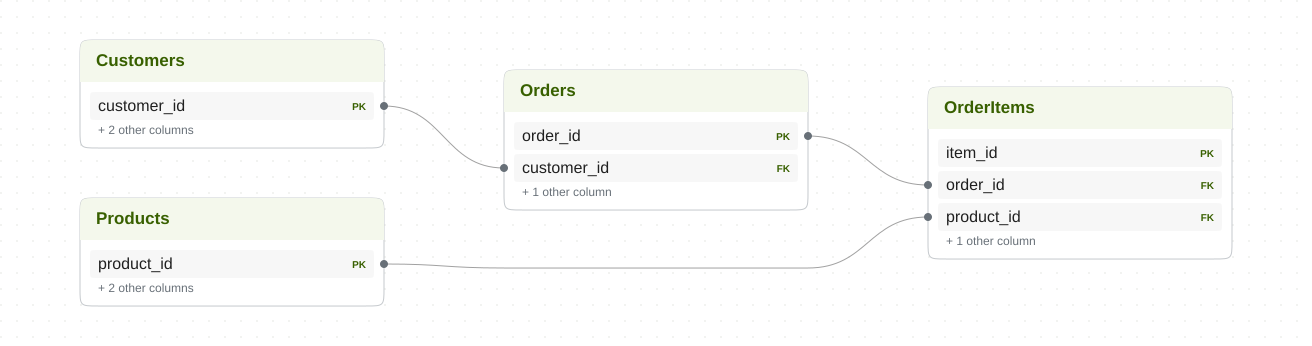

In [4]:
graph.visualize()

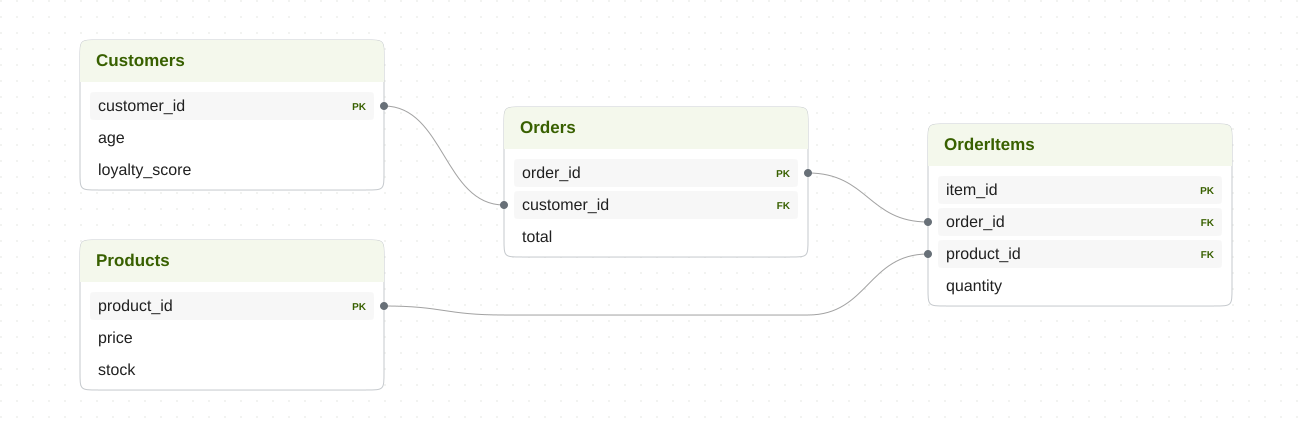

In [5]:
graph.visualize(show_cols=True)

Export both views as SVG files in this run's directory.


In [6]:
keys_svg = demo_directory / "relationships.svg"
detail_svg = demo_directory / "relationships-with-columns.svg"
graph.visualize(keys_svg)
graph.visualize(detail_svg, show_cols=True)
print(f"Saved graph, keys-only SVG: {keys_svg}")
print(f"Saved graph, detailed SVG:  {detail_svg}")

Saved graph, keys-only SVG: /tmp/kumo-notebook-runs/local_kumo_engine_graph_visualization_preview/20261109T183010Z/kumo-visualizer-demo-osj0oqv0/relationships.svg
Saved graph, detailed SVG:  /tmp/kumo-notebook-runs/local_kumo_engine_graph_visualization_preview/20261109T183010Z/kumo-visualizer-demo-osj0oqv0/relationships-with-columns.svg


## Adapt the example to your graph

Replace the four synthetic `Table` objects with your resolved tables and update the aliases and `Edge` definitions.
Display relationships and export SVG diagrams without ingesting a snapshot or training a model.


## Continue with batch predictions

This example prepares a graph without training a model. To run inference on newly added rows, follow [the custom training-table batch example](local_kumo_engine_custom_training_table.ipynb#Batch-predictions): reserve unlabeled customers, add them after fitting, refresh the snapshot, and pass their IDs in a prediction table.
For a temporal example with explicit scoring times and observed history, see [appointment attendance](../../healthcare/notebooks/local_kumo_engine_synthetic_appointment_attendance.ipynb#Batch-predictions).
